# Customer Churn – EDA & Feature Selection
Goal: choose the variables to feed into Logistic Regression, Decision Tree, SVM and Random Forest.

Approach
1. Remove leakage columns (known only after churn, or outputs of an earlier model)
2. EDA – target balance, missing values, distributions, churn rate by variable
3. **Information Gain** (entropy reduction) for every candidate variable
4. **Chi-square test of independence** + Cramér's V (effect size)
5. Redundancy check (correlation between predictors)
6. Final variable list

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import chi2_contingency
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)

PATH = "/mnt/user-data/uploads/E-commerce_Customer_Churn_2026.csv"   # change to your local path
df = pd.read_csv(PATH)
TARGET = "churn_flag"
print(df.shape)

(50000, 48)


## 1. Drop leakage columns
These are filled in only for churned customers, describe actions taken after churn,
or are scores from a previous model. Keeping them would give near-100% accuracy that is meaningless.

In [2]:
LEAK = ["churn_id", "customer_id", "is_churned", "churn_date", "days_since_churn", "churn_reason",
        "churn_category", "churn_risk_score", "churn_probability", "prevention_method",
        "predicted_churn", "is_high_risk_customer", "retention_probability", "churn_rate_indicator",
        "churn_risk_category", "churn_revenue_impact_usd", "recovery_revenue_usd",
        "customer_retention_cost_usd", "customer_health_score", "customer_health_category",
        "dataset_year", "customer_city"]   # city: high-cardinality, country kept instead
data = df.drop(columns=LEAK)
CANDIDATES = [c for c in data.columns if c != TARGET]
CAT = [c for c in CANDIDATES if data[c].dtype == object or str(data[c].dtype) == "str"]
NUM = [c for c in CANDIDATES if c not in CAT]
print(f"{len(CANDIDATES)} candidate variables: {len(NUM)} numeric, {len(CAT)} categorical")

25 candidate variables: 17 numeric, 8 categorical


## 2. EDA
### 2.1 Target balance and missing values

In [3]:
print(data[TARGET].value_counts(normalize=True).rename("share").round(3))
miss = data[CANDIDATES].isna().mean().sort_values(ascending=False)
print("\nMissing share:\n", miss[miss > 0].round(3))

churn_flag
0    0.587
1    0.413
Name: share, dtype: float64

Missing share:
 social_media_engagement    0.300
subscription_type          0.263
dtype: float64


Missing values in `subscription_type` (26%) and `social_media_engagement` (30%) are kept as a
separate **"Missing"** level, because missingness itself can carry signal.

In [4]:
for c in CAT:
    data[c] = data[c].fillna("Missing")

### 2.2 Numeric variables: distribution by churn status

churn_flag                          0         1  diff_pct
customer_age_months             30.26     29.96     -1.00
total_spend_usd              25045.99  25029.94     -0.06
avg_order_value_usd           2300.62   2209.84     -3.95
num_purchases                   24.34     24.74      1.65
satisfaction_score               3.32      2.57    -22.73
support_tickets                  8.62     10.52     22.01
returns_count                    4.32      4.80     11.06
days_since_last_purchase        93.82    106.98     14.02
customer_lifetime_value_usd  26275.04  26275.07      0.00
support_interactions             6.32      7.25     14.57
feedback_score                   5.52      5.50     -0.33
loyalty_score                   49.90     50.35      0.89
marketing_emails_sent           24.48     24.27     -0.85
marketing_emails_opened         12.24     12.18     -0.50
marketing_emails_clicked        12.26     12.25     -0.04
marketing_conversions            3.13      3.09     -1.29
referral_count

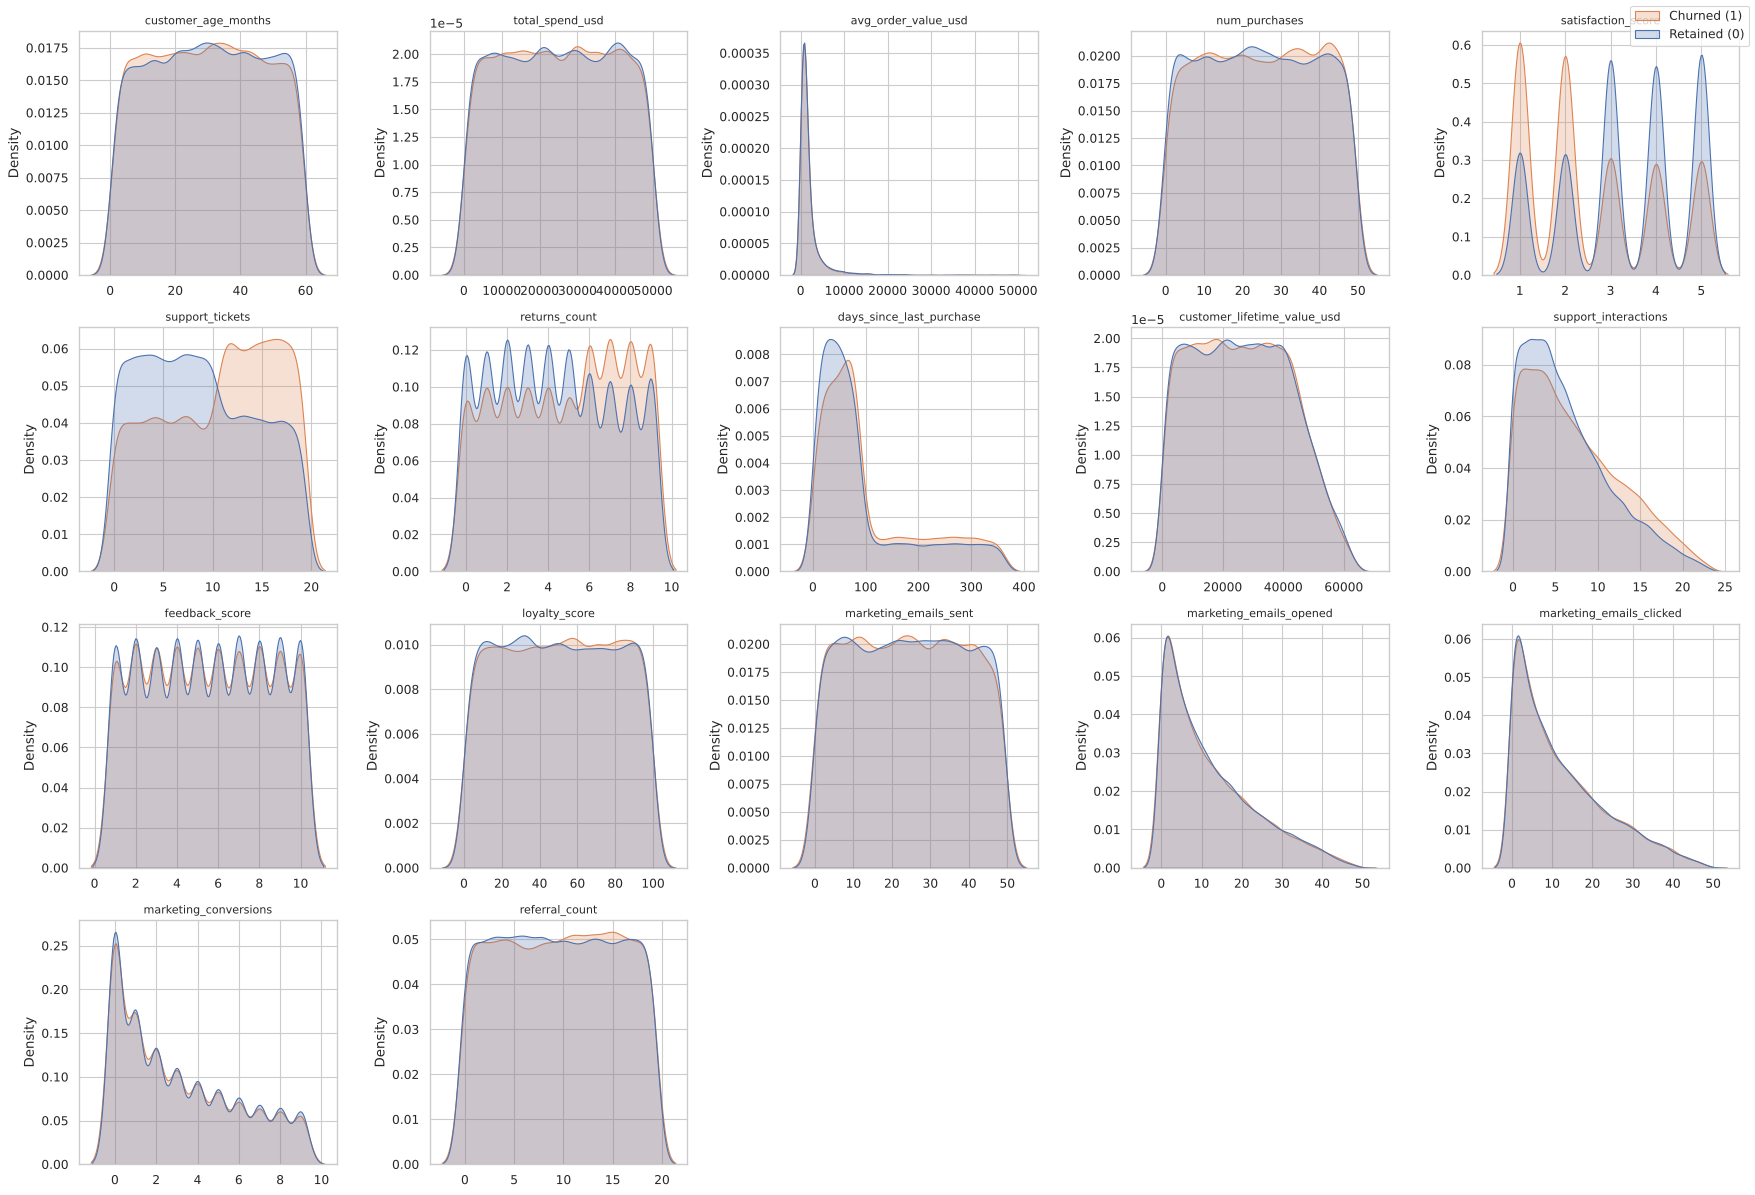

In [5]:
fig, axes = plt.subplots(4, 5, figsize=(22, 15)); axes = axes.ravel()
for ax, c in zip(axes, NUM):
    sns.kdeplot(data=data, x=c, hue=TARGET, common_norm=False, fill=True, ax=ax, legend=False)
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
for ax in axes[len(NUM):]: ax.axis("off")
fig.legend(["Churned (1)", "Retained (0)"], loc="upper right"); plt.tight_layout()
plt.savefig("fig_numeric_kde.png", dpi=90); plt.show()

print(data.groupby(TARGET)[NUM].mean().T.assign(diff_pct=lambda t: (t[1] / t[0] - 1) * 100).round(2))

### 2.3 Categorical variables: churn rate by level

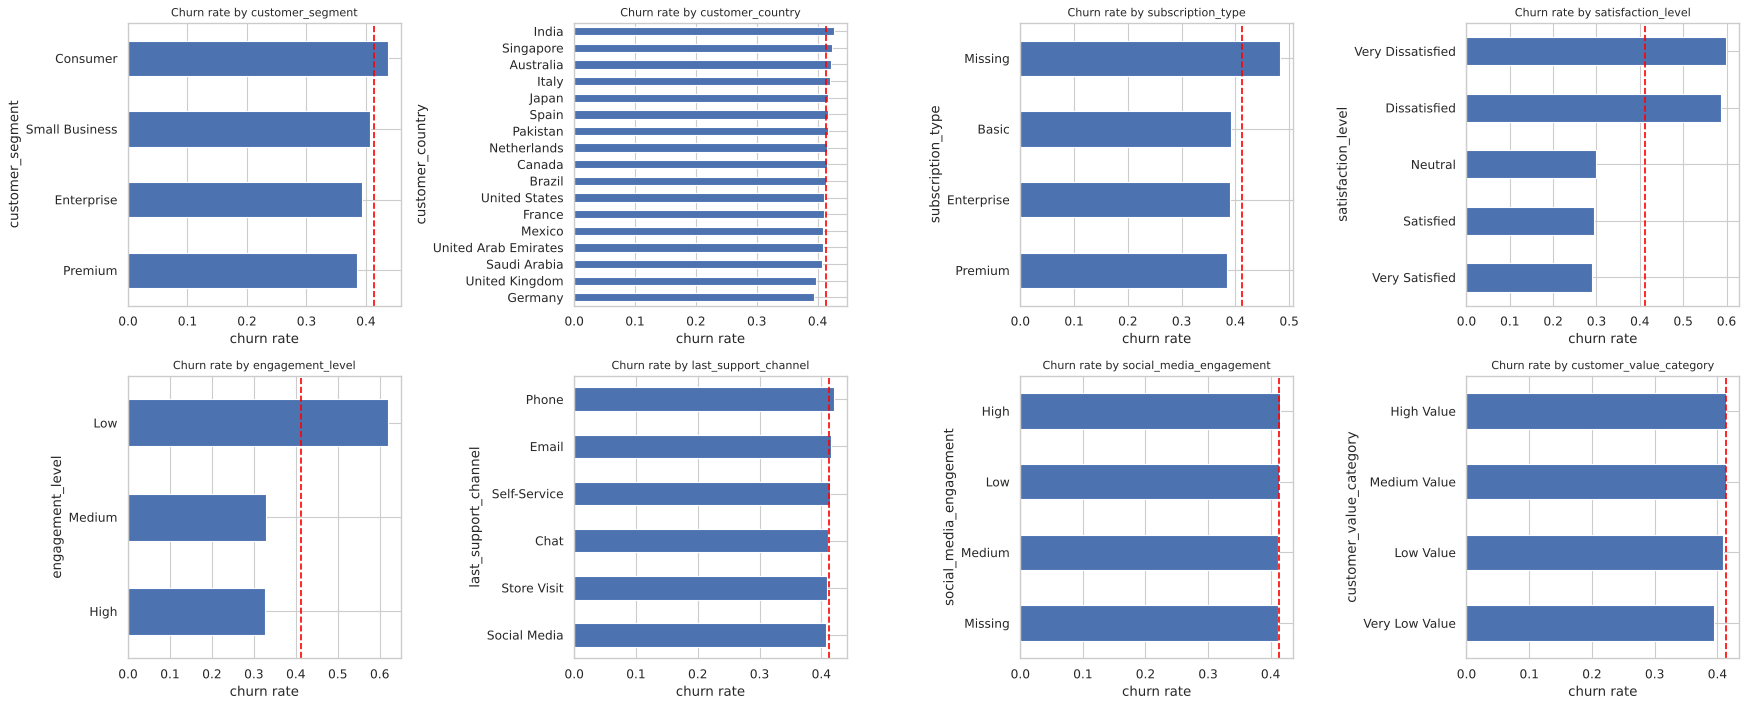

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9)); axes = axes.ravel()
for ax, c in zip(axes, CAT):
    rate = data.groupby(c)[TARGET].mean().sort_values()
    rate.plot.barh(ax=ax, color="#4C72B0"); ax.axvline(data[TARGET].mean(), color="red", ls="--")
    ax.set_title(f"Churn rate by {c}", fontsize=10); ax.set_xlabel("churn rate")
for ax in axes[len(CAT):]: ax.axis("off")
plt.tight_layout(); plt.savefig("fig_categorical_rates.png", dpi=90); plt.show()

## 3. Information Gain
IG(Y, X) = H(Y) − H(Y | X), using entropy in bits.
Numeric variables are discretised into deciles (equal-frequency bins) first, so every variable is
judged on a comparable basis. **Gain Ratio** (IG ÷ split entropy of X) is also shown, because plain IG
favours variables with many levels (e.g. country with 17 levels vs engagement with 3).

In [7]:
def entropy(p):
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

def discretise(s, bins=10):
    if s.dtype == object or str(s.dtype) == "str" or s.nunique() <= bins:
        return s.astype(str)
    return pd.qcut(s, q=bins, duplicates="drop").astype(str)

H_Y = entropy(data[TARGET].value_counts(normalize=True).values)
rows = []
binned = {}
for c in CANDIDATES:
    x = discretise(data[c]); binned[c] = x
    px = x.value_counts(normalize=True)
    h_cond = sum(px[v] * entropy(data.loc[x == v, TARGET].value_counts(normalize=True).values) for v in px.index)
    ig = H_Y - h_cond
    split_info = entropy(px.values)
    rows.append({"variable": c, "type": "categorical" if c in CAT else "numeric", "levels/bins": len(px),
                 "info_gain": ig, "gain_ratio": ig / split_info if split_info else 0})
ig_df = pd.DataFrame(rows).sort_values("info_gain", ascending=False).reset_index(drop=True)
print(f"H(churn) = {H_Y:.4f} bits")
print(ig_df.round(5).to_string())

H(churn) = 0.9781 bits
                       variable         type  levels/bins  info_gain  gain_ratio
0            satisfaction_score      numeric            5    0.06391     0.02753
1            satisfaction_level  categorical            5    0.06391     0.02753
2              engagement_level  categorical            3    0.05224     0.03330
3               support_tickets      numeric           10    0.02286     0.00688
4                 returns_count      numeric           10    0.00689     0.00208
5      days_since_last_purchase      numeric           10    0.00671     0.00202
6          support_interactions      numeric           10    0.00600     0.00184
7             subscription_type  categorical            4    0.00516     0.00281
8              customer_segment  categorical            4    0.00146     0.00080
9                 num_purchases      numeric           10    0.00044     0.00013
10          avg_order_value_usd      numeric           10    0.00022     0.00007
11   

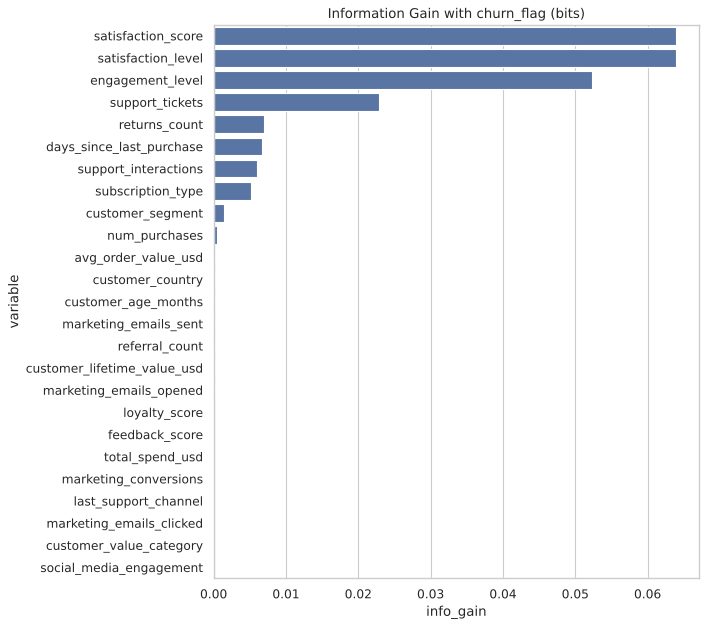

In [8]:
plt.figure(figsize=(9, 8))
sns.barplot(data=ig_df, y="variable", x="info_gain", color="#4C72B0")
plt.title("Information Gain with churn_flag (bits)"); plt.tight_layout()
plt.savefig("fig_information_gain.png", dpi=90); plt.show()

## 4. Chi-square test of independence + Cramér's V
H0: the variable and churn are independent. With 50,000 rows, the test has huge power, so even a
tiny, useless difference can come out "significant". That is why **Cramér's V** (effect size, 0–1)
is reported alongside the p-value, and decisions use both.

In [9]:
chi_rows = []
for c in CANDIDATES:
    ct = pd.crosstab(binned[c], data[TARGET])
    chi2, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    chi_rows.append({"variable": c, "chi2": chi2, "dof": dof, "p_value": p, "cramers_v": v})
chi_df = pd.DataFrame(chi_rows)

summary = ig_df.merge(chi_df, on="variable")
summary["significant_5pct"] = summary["p_value"] < 0.05
print(summary[["variable", "type", "info_gain", "gain_ratio", "chi2", "dof", "p_value", "cramers_v",
               "significant_5pct"]].to_string(float_format=lambda v: f"{v:.4g}"))

                       variable         type  info_gain  gain_ratio   chi2  dof   p_value  cramers_v  significant_5pct
0            satisfaction_score      numeric    0.06391     0.02753   4413    4         0     0.2971              True
1            satisfaction_level  categorical    0.06391     0.02753   4413    4         0     0.2971              True
2              engagement_level  categorical    0.05224      0.0333   3643    2         0     0.2699              True
3               support_tickets      numeric    0.02286    0.006883   1581    9         0     0.1778              True
4                 returns_count      numeric   0.006895    0.002076    479    9 1.794e-97    0.09788              True
5      days_since_last_purchase      numeric   0.006709     0.00202  463.5    9   3.8e-94    0.09628              True
6          support_interactions      numeric   0.005996    0.001841  419.1    9 1.137e-84    0.09156              True
7             subscription_type  categorical   0

## 5. Redundancy check
Two predictors that carry the same information should not both go into the model
(it inflates Logistic Regression coefficients and splits importance in tree models).

Highly correlated numeric pairs (|rho| > 0.7):
             level_0                      level_1       rho
25  total_spend_usd  customer_lifetime_value_usd  0.969858

satisfaction_level vs satisfaction_score:
 satisfaction_score      1     2      3     4      5
satisfaction_level                                 
Dissatisfied            0  9702      0     0      0
Neutral                 0     0  10148     0      0
Satisfied               0     0      0  9800      0
Very Dissatisfied   10099     0      0     0      0
Very Satisfied          0     0      0     0  10251

customer_value_category vs total_spend (median):
                               min     median       max
customer_value_category                               
High Value               10000.26  29990.450  49998.30
Low Value                 1003.52   2940.490   4996.41
Medium Value              5005.67   7507.725   9999.14
Very Low Value               0.72    499.560    996.36


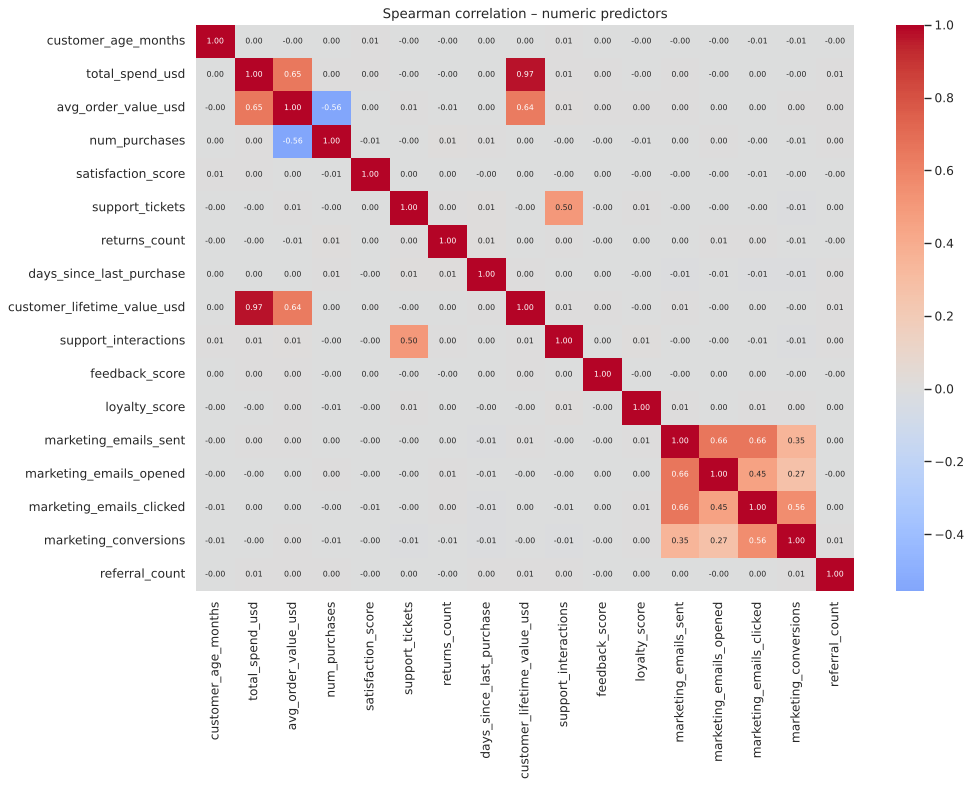

In [10]:
corr = data[NUM].corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman correlation – numeric predictors"); plt.tight_layout()
plt.savefig("fig_correlation.png", dpi=90); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
         .rename("rho").reset_index().query("abs(rho) > 0.7"))
print("Highly correlated numeric pairs (|rho| > 0.7):\n", pairs)

# categorical duplicates of numeric columns
print("\nsatisfaction_level vs satisfaction_score:\n", pd.crosstab(data.satisfaction_level, data.satisfaction_score))
print("\ncustomer_value_category vs total_spend (median):\n",
      data.groupby("customer_value_category")["total_spend_usd"].agg(["min", "median", "max"]))

## 6. Selection rule
A variable is kept when **all** of these hold:
* chi-square p < 0.05, **and**
* Cramér's V ≥ 0.02 (otherwise the association is statistically real but practically negligible), **and**
* it is not a duplicate of a stronger variable (section 5).

In [11]:
IG_MIN, V_MIN = 0.0005, 0.02
summary["keep_stat"] = summary.significant_5pct & (summary.cramers_v >= V_MIN) & (summary.info_gain >= IG_MIN)
print(summary[["variable", "info_gain", "cramers_v", "p_value", "keep_stat"]]
      .to_string(float_format=lambda v: f"{v:.4g}"))
summary.to_csv("feature_selection_summary.csv", index=False)

                       variable  info_gain  cramers_v   p_value  keep_stat
0            satisfaction_score    0.06391     0.2971         0       True
1            satisfaction_level    0.06391     0.2971         0       True
2              engagement_level    0.05224     0.2699         0       True
3               support_tickets    0.02286     0.1778         0       True
4                 returns_count   0.006895    0.09788 1.794e-97       True
5      days_since_last_purchase   0.006709    0.09628   3.8e-94       True
6          support_interactions   0.005996    0.09156 1.137e-84       True
7             subscription_type   0.005155    0.08487 9.495e-78       True
8              customer_segment   0.001462    0.04501 8.229e-22       True
9                 num_purchases  0.0004412     0.0247 0.0003595      False
10          avg_order_value_usd  0.0002185    0.01738   0.08793      False
11             customer_country    0.00021    0.01705    0.5591      False
12          customer_age_

## 7. Final variable list
* `satisfaction_level` is an exact one-to-one relabel of `satisfaction_score` → keep only the score.
* `customer_lifetime_value_usd` and `total_spend_usd` are 0.97 correlated, and both fail the test anyway.
* `num_purchases` is borderline: significant (p ≈ 0.0004) but tiny effect (V = 0.025, IG = 0.0004).
  It is left out here; you may test it as an optional add-on.

In [12]:
SELECTED = ["satisfaction_score", "engagement_level", "support_tickets", "returns_count",
            "days_since_last_purchase", "support_interactions", "subscription_type", "customer_segment"]
print("Selected variables:", SELECTED)

Selected variables: ['satisfaction_score', 'engagement_level', 'support_tickets', 'returns_count', 'days_since_last_purchase', 'support_interactions', 'subscription_type', 'customer_segment']


## 8. Sanity check: does dropping 17 variables cost accuracy?
Quick 5-fold cross-validated ROC-AUC, selected 8 vs all 25 candidates.

In [13]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def auc(cols, model):
    cat = [c for c in cols if c in CAT]; num = [c for c in cols if c not in CAT]
    pre = ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore"), cat)])
    cv = StratifiedKFold(5, shuffle=True, random_state=42)
    return cross_val_score(make_pipeline(pre, model), data[cols], data[TARGET], cv=cv, scoring="roc_auc").mean()

all_cols = [c for c in CANDIDATES if c != "satisfaction_level"]
for name, m in [("Logistic Regression", LogisticRegression(max_iter=2000)),
                ("Random Forest", RandomForestClassifier(300, min_samples_leaf=20, n_jobs=-1, random_state=0))]:
    print(f"{name:20s}  all {len(all_cols)} vars: {auc(all_cols, m):.4f}   selected {len(SELECTED)} vars: {auc(SELECTED, m):.4f}")

Logistic Regression   all 24 vars: 0.7493   selected 8 vars: 0.7499
Random Forest         all 24 vars: 0.7696   selected 8 vars: 0.7693
